# Loops and TADs
Users might be interested in displaying any higher order chromatin organisations (loops, TADs) alongside synteny. Thats why this functional was added. Here in this notebook we tested it before writting function that goes to functions.py

Pls run from the SynViser folder.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Arc, Polygon

%matplotlib inline

## 1. Read the loop
Input is .bedpe and it has six columns: chromosome, start and end for each anchor. This example file has one loop.

In [13]:
loops = pd.read_csv("example_data/loops_demo.bedpe", sep="\t", header=None, names=["chr1", "start1", "end1", "chr2", "start2", "end2"])
loops

,chr1,start1,end1,chr2,start2,end2
0,chrA,1180000,1220000,chrA,4780000,4820000


## 2. Find the anchor centres

Same as before, to place something on a chr we need to figure out its relative position. For that we find the centre of anchor1 and then anchor2, and divide each by chr size.

Lets say we have the loop from example chrA:1180000-1220000 to chrA:4780000-4820000.

For the first anchor, the centre is then (1_180_000 + 1_220_000) / 2= 1_200_000.

The relative position is centre/chr_size, hence 1_200_000 / 6_000_000 = 0.2. Hence centre of this anchor sits at 20% of chr length.

Puted in code gives us:

In [17]:
chr_size = 6_000_000

x1 = (loops.start1[0] + loops.end1[0]) / 2 / chr_size
x2 = (loops.start2[0] + loops.end2[0]) / 2 / chr_size
print(x1, x2)

0.2 0.8


## 3. Draw the loop

Previous block gave us all what was needed for the display as now we have first and second anchor (x1, x2). 

To draw loop we use `Arc`. 

We again figure out where the center sits (x1 + x2) / 2 and width is x2 - x1. We then put it at y=0.05 so it starts on top of chr and not covered by it.

As for arch itself theta1=0 and theta2=180 give us *only* the upper half of the ellipse (otherwise we would get the whole elipse).

Then for height I just eyeballed it to be 0.5.

Put in code gives us:

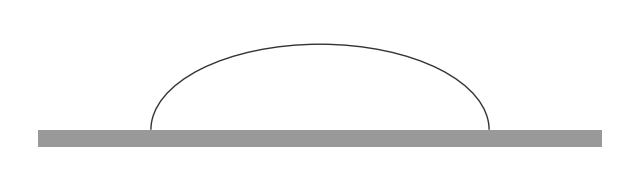

In [18]:
fig, ax = plt.subplots(figsize=(8, 2))
ax.add_patch(Rectangle((0, 0), 1, 0.05, facecolor="#999999"))
ax.add_patch(Arc(((x1 + x2) / 2, 0.05), x2 - x1, 0.5, theta1=0, theta2=180, color="#333333"))
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 0.4)
ax.axis("off")
plt.show()

## 4. Draw a TAD

TADs are comming in BED and we already delt with BED format before

In [19]:
tads = pd.read_csv("example_data/tads_chrA_demo.bed", sep="\t", header=None, names=["chrom", "start", "end"])
tads

,chrom,start,end
0,chrA,1200000,4800000


We just normalise TAD boundaries position and plot as rectangle wiht Polygon().

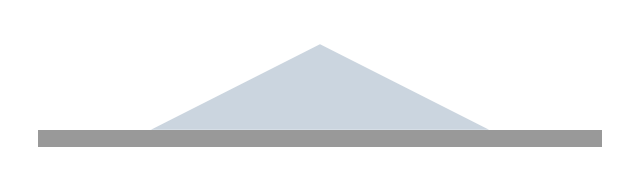

In [21]:
left = tads.start[0] / chr_size
right = tads.end[0] / chr_size

fig, ax = plt.subplots(figsize=(8, 2))
ax.add_patch(Rectangle((0, 0), 1, 0.05, facecolor="#999999"))
ax.add_patch(Polygon([(left, 0.05), ((left + right) / 2, 0.3), (right, 0.05)],facecolor="#cbd5df", edgecolor="none"))
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 0.4)
ax.axis("off")
plt.show()

To-Do: 
- make it looking nicer
- adjust loop line width and heihgt
- loops as dashed lines ?